In [1]:
import pandas as pd

META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"

meta = pd.read_csv(META_FILE)
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.lower()

site_counts = meta["metastatic_sites"].value_counts()

print("Top 5 sites by sample count:")
print(site_counts.head())

top3 = site_counts.head(3).index.tolist()
print("\nTop 3 sites:", top3)

Top 5 sites by sample count:
liver    53
brain    19
bone     17
ln       10
lung      5
Name: metastatic_sites, dtype: int64

Top 3 sites: ['liver', 'brain', 'bone']


In [44]:
import pandas as pd

MASKED = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.top1000.with_site_direction.tsv"
UNMASKED = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.top1000.with_site_direction.tsv"

# Load
df_mask = pd.read_csv(MASKED, sep="\t")
df_unmask = pd.read_csv(UNMASKED, sep="\t")

# BH-significant only
df_mask = df_mask[df_mask["kw_q_BH"] < 0.05]
df_unmask = df_unmask[df_unmask["kw_q_BH"] < 0.05]

print("Masked significant bins:", df_mask.shape[0])
print("Unmasked significant bins:", df_unmask.shape[0])

# Count site_highest
mask_counts = df_mask["site_highest"].value_counts()
unmask_counts = df_unmask["site_highest"].value_counts()

print("\nMasked site_highest counts:")
print(mask_counts)

print("\nUnmasked site_highest counts:")
print(unmask_counts)

# Combine into comparison table
comparison = pd.concat(
    [mask_counts.rename("masked"),
     unmask_counts.rename("unmasked")],
    axis=1
).fillna(0).astype(int)

print("\nComparison table:")
print(comparison)

Masked significant bins: 986
Unmasked significant bins: 990

Masked site_highest counts:
liver    872
bone     114
Name: site_highest, dtype: int64

Unmasked site_highest counts:
liver    880
bone     109
brain      1
Name: site_highest, dtype: int64

Comparison table:
       masked  unmasked
liver     872       880
bone      114       109
brain       0         1


<Figure size 600x400 with 0 Axes>

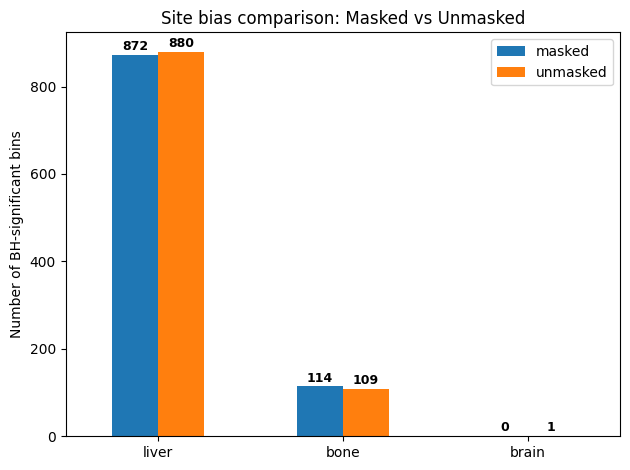

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Comparison_CNV_noCNV/Site_bias_comparison_masked_vs_unmasked.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Comparison_CNV_noCNV/Site_bias_comparison_masked_vs_unmasked.pdf


In [51]:
import os
import matplotlib.pyplot as plt

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Comparison_CNV_noCNV/"
os.makedirs(OUTDIR, exist_ok=True)

plot_df = comparison[["masked", "unmasked"]]

plt.figure(figsize=(6,4))

ax = plot_df.plot(kind="bar")

plt.ylabel("Number of BH-significant bins")
plt.title("Site bias comparison: Masked vs Unmasked")
plt.xticks(rotation=0)
# ---- Add numeric labels ----
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + max(plot_df.max())*0.005,
            f"{int(height)}",
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold'
        )

plt.tight_layout()

out_png = os.path.join(OUTDIR, "Site_bias_comparison_masked_vs_unmasked.png")
out_pdf = os.path.join(OUTDIR, "Site_bias_comparison_masked_vs_unmasked.pdf")

plt.savefig(out_png, dpi=300)
plt.savefig(out_pdf)

plt.show()

print("Saved:")
print(out_png)
print(out_pdf)

Masked significant (A): 986
Unmasked significant (B): 990
Intersection (A∩B): 819
Union (A∪B): 1157
Jaccard = 0.7079
Masked-only (A\B): 167
Unmasked-only (B\A): 171


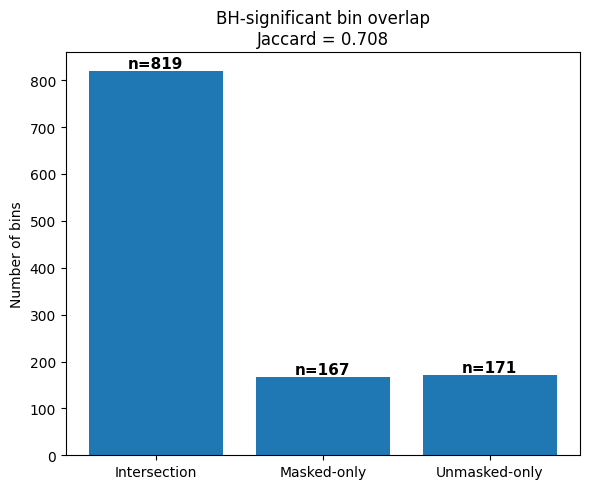

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

MASKED = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.BHsig.with_site_direction.with_genes.tsv"
UNMASKED = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size_no_cnv_masking/KW_BH/KW_BH.no_cnv_masking.BHsig.with_site_direction.with_genes.tsv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Comparison_CNV_noCNV/"
os.makedirs(OUTDIR, exist_ok=True)

df_mask = pd.read_csv(MASKED, sep="\t", dtype={"bin_id": str})
df_unmask = pd.read_csv(UNMASKED, sep="\t", dtype={"bin_id": str})

# Significant sets
A = set(df_mask["bin_id"].astype(str))
B = set(df_unmask["bin_id"].astype(str))

inter = len(A & B)
union = len(A | B)
jacc = inter / union if union else np.nan

only_A = len(A - B)
only_B = len(B - A)

print("Masked significant (A):", len(A))
print("Unmasked significant (B):", len(B))
print("Intersection (A∩B):", inter)
print("Union (A∪B):", union)
print(f"Jaccard = {jacc:.4f}")
print("Masked-only (A\\B):", only_A)
print("Unmasked-only (B\\A):", only_B)

# =========================
# Plot
# =========================

plt.figure(figsize=(6,5))

bars = ["Intersection", "Masked-only", "Unmasked-only"]
values = [inter, only_A, only_B]

bars_plot = plt.bar(bars, values)

plt.title(f"BH-significant bin overlap\nJaccard = {jacc:.3f}")
plt.ylabel("Number of bins")

# ---- Add simple n= labels above bars ----
for i, v in enumerate(values):
    plt.text(
        i,
        v + max(values)*0.0,   # small vertical offset
        f"n={v}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

out_png = os.path.join(OUTDIR, "Jaccard_overlap_breakdown.png")
out_pdf = os.path.join(OUTDIR, "Jaccard_overlap_breakdown.pdf")

plt.savefig(out_png, dpi=300)
plt.savefig(out_pdf)
plt.show()